In [1]:
from Preprocessing import * 

In [9]:
feat_30_df = pd.read_csv('features_30_sec.csv', sep=',')
feat_3_df = pd.read_csv('features_3_sec.csv', sep=',')
target_column = "label"

In [10]:
feat_3_df.head()

,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.0.wav,66149,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,...,39.687145,-3.241280,36.488243,0.722209,38.099152,-5.050335,33.618073,-0.243027,43.771767,blues
1,blues.00000.1.wav,66149,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,...,64.748276,-6.055294,40.677654,0.159015,51.264091,-2.837699,97.030830,5.784063,59.943081,blues
2,blues.00000.2.wav,66149,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,...,67.336563,-1.768610,28.348579,2.378768,45.717648,-1.938424,53.050835,2.517375,33.105122,blues
3,blues.00000.3.wav,66149,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,...,47.739452,-3.841155,28.337118,1.218588,34.770935,-3.580352,50.836224,3.630866,32.023678,blues
4,blues.00000.4.wav,66149,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,...,30.336359,0.664582,45.880913,1.689446,51.363583,-3.392489,26.738789,0.536961,29.146694,blues


In [15]:
def audit_partitions(prep_30s, prep_3s):
    # Obtener los identificadores únicos por partición
    train_30 = set(prep_30s.groups_train.unique())
    test_30 = set(prep_30s.groups_test.unique())

    train_3 = set(prep_3s.groups_train.unique())
    test_3 = set(prep_3s.groups_test.unique())

    # 1. Ninguna canción puede estar en train y test
    assert train_30.isdisjoint(test_30), (
        "Leakage en el dataset de canciones completas"
    )
    assert train_3.isdisjoint(test_3), (
        "Leakage en el dataset de fragmentos"
    )

    # 2. Comparar las particiones de las canciones compartidas
    shared = (
        (train_30 | test_30)
        & (train_3 | test_3)
    )

    mismatches = {
        song for song in shared
        if ((song in test_30) != (song in test_3))
    }

    assert not mismatches, (
        f"Particiones inconsistentes: {len(mismatches)} canciones. "
        f"Ejemplos: {list(mismatches)[:10]}"
    )

    # 3. Resumen de resultados
    print("Auditoría superada.")
    print(f"Canciones compartidas: {len(shared)}")
    print(f"Train 30 s: {len(train_30)} canciones")
    print(f"Test 30 s:  {len(test_30)} canciones")
    print(f"Train 3 s:  {len(train_3)} canciones")
    print(f"Test 3 s:   {len(test_3)} canciones")
    print("No hay solapamiento train/test.")
    print("Las canciones compartidas tienen la misma partición.")

    return True

Para tener el mismo train y test en los dos: 

In [16]:
# 1. Dataset de canciones completas
prep_30s = Preprocessing(
    feat_30_df,
    y_name="label",
    group_col="filename",
    test_size=0.20,
    random_state=42,
    drop_duplicates=False,
)

prep_30s.run()

test_songs_30s = set(prep_30s.groups_test.unique())


# 2. Dataset de fragmentos de 3 segundos
prep_3s = Preprocessing(
    feat_3_df,
    y_name="label",
    group_col="filename",
    test_size=0.20,
    random_state=42,
    test_groups=test_songs_30s,
    drop_duplicates=False,
)

prep_3s.run()


# 3. Comprobar la integridad de las particiones
audit_partitions(prep_30s, prep_3s)


# 4. Recuperar los datos
X_train_30s, X_test_30s, y_train_30s, y_test_30s = (
    prep_30s.get_data()
)

X_train_3s, X_test_3s, y_train_3s, y_test_3s = (
    prep_3s.get_data()
)

meta_train_30s, meta_test_30s = prep_30s.get_meta()
meta_train_3s, meta_test_3s = prep_3s.get_meta()

=== Cleaning ===
Songs found: 1000
Dropped columns: ['filename']
Rows without target removed: 0
Final shape: (1000, 61)

X: (1000, 58) | y: (1000,)

=== Train / test split (80% / 20%) ===
Split by song -> train: 800 songs | test: 200 songs
Train: (800, 58) | Test: (200, 58)

Class proportions (train vs test):
           train  test
label                 
blues        0.1   0.1
classical    0.1   0.1
country      0.1   0.1
disco        0.1   0.1
hiphop       0.1   0.1
jazz         0.1   0.1
metal        0.1   0.1
pop          0.1   0.1
reggae       0.1   0.1
rock         0.1   0.1

=== Categorical encoding ===
No categorical features to encode.

=== Constant columns removed (0) ===

=== Target encoding ===
0 -> blues
1 -> classical
2 -> country
3 -> disco
4 -> hiphop
5 -> jazz
6 -> metal
7 -> pop
8 -> reggae
9 -> rock
=== Cleaning ===
Songs found: 1000
Dropped columns: ['filename']
Rows without target removed: 0
Final shape: (9990, 61)

X: (9990, 58) | y: (9990,)

=== Train / test split

In [18]:
from Models import * 

Evaluating 12 pipelines with 10-fold stratified CV on the training set...
  - Logistic Regression | Sin selección
  - Logistic Regression | ANOVA k=50
  - Logistic Regression | L1 logística
  - Logistic Regression | PCA 95%
  - Random Forest | Sin selección
  - Random Forest | ANOVA k=50
  - Random Forest | L1 logística
  - Random Forest | PCA 95%
  - Voting Ensemble | Sin selección
  - Voting Ensemble | ANOVA k=50
  - Voting Ensemble | L1 logística
  - Voting Ensemble | PCA 95%

CROSS-VALIDATION RESULTS
                               Name  Train Acc  Val Acc  Val Acc Std    Gap  Val F1  N features
       Random Forest | L1 logística     0.9989   0.7863       0.0405 0.2126  0.7818     52.1000
      Random Forest | Sin selección     0.9989   0.7750       0.0349 0.2239  0.7698     58.0000
     Voting Ensemble | L1 logística     0.9989   0.7750       0.0391 0.2239  0.7723     52.1000
    Voting Ensemble | Sin selección     0.9989   0.7700       0.0359 0.2289  0.7663     58.0000
       Vot

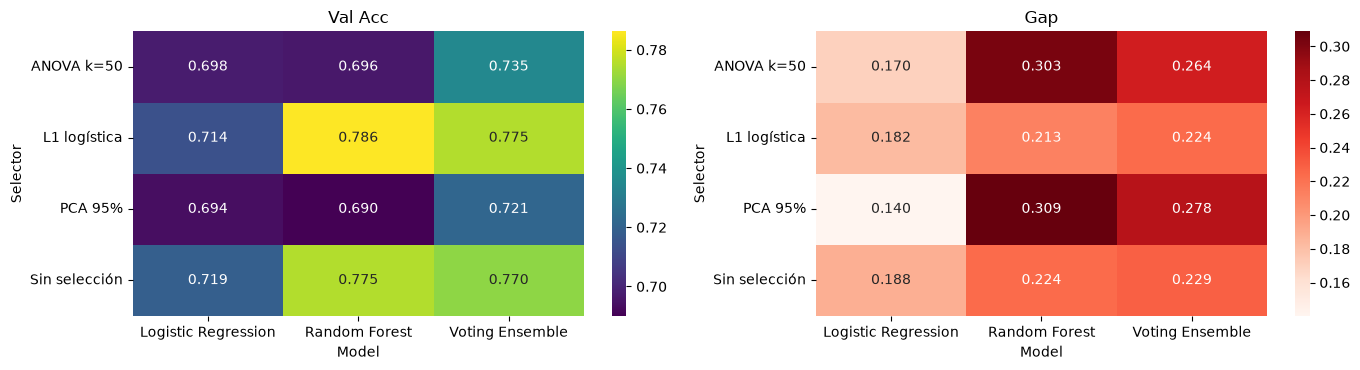

In [20]:
models = Models(X_train_30s, y_train_30s, label_encoder=prep_30s.encoder)
fs = models.fs

# 1. Comparar modelos y selectores
models.build_models(
    ["logistic", "random_forest", "voting"],
    selectors={
        "Sin selección": "passthrough",
        "ANOVA k=50": fs.make("anova", 50),
        "L1 logística": fs.make("l1_logistic"),
        "PCA 95%": fs.make("pca_var", 0.95),
    },
)

# 2. Evaluar todas las combinaciones usando validación cruzada
results = models.evaluate_all()

# Ver el mejor selector de cada modelo
models.best_per_model()

# Visualizar resultados
models.plot_grid()


[Random Forest | L1 logística] nested CV accuracy: 0.7700 ± 0.0317
Parameters chosen per fold:
  4x {'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 500}
  3x {'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 200}
  2x {'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 200}
  1x {'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__min_samples_split': 10, 'model__n_estimators': 200}
Best parameters (full train): {'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 200}
best_model -> Random Forest | L1 logística (tuned)
Model: Random Forest | L1 logística (tuned)
Test accuracy: 0.7900
Test macro F1: 0.7875

Classification report:
              precision    recall  f1-score   support

       blues       0.75      0.75      0.75        20
   classical

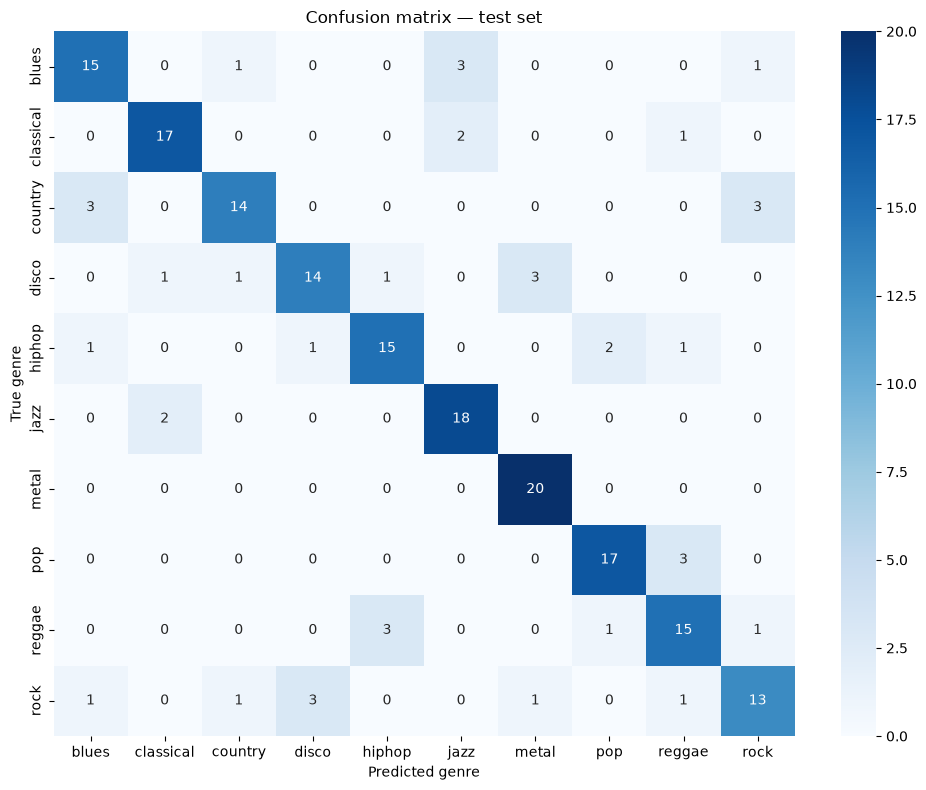

array([0, 2, 0, 5, 5, 0, 0, 0, 0, 0, 0, 9, 0, 0, 0, 0, 0, 0, 0, 5, 1, 1,
       1, 1, 1, 1, 1, 1, 5, 8, 1, 5, 1, 1, 1, 1, 1, 1, 1, 1, 2, 9, 2, 2,
       2, 2, 2, 2, 2, 2, 0, 9, 0, 9, 0, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3,
       2, 1, 3, 3, 4, 3, 3, 6, 3, 6, 3, 6, 3, 3, 8, 4, 4, 4, 0, 3, 4, 4,
       4, 4, 4, 4, 4, 4, 7, 7, 4, 4, 4, 4, 1, 5, 5, 5, 5, 5, 5, 5, 5, 5,
       5, 5, 5, 5, 5, 5, 5, 5, 1, 5, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
       6, 6, 6, 6, 6, 6, 6, 6, 8, 7, 7, 7, 7, 7, 8, 7, 8, 7, 7, 7, 7, 7,
       7, 7, 7, 7, 7, 7, 8, 8, 8, 9, 4, 8, 8, 8, 8, 8, 8, 8, 4, 8, 8, 8,
       4, 8, 7, 8, 9, 2, 0, 8, 9, 9, 9, 3, 3, 3, 9, 9, 9, 9, 9, 9, 9, 9,
       9, 6])

In [22]:
best, info = models.grid_search(
    "Random Forest | L1 logística",
    {
        "model__n_estimators": [200, 500],
        "model__max_depth": [10, 20],
        "model__min_samples_split": [2, 10],
        "model__min_samples_leaf": [2, 4],
    },
)

models.evaluate_on_test(X_test_30s, y_test_30s)

## Three second dataset

Assessment of Overfitting: curva de aprendizaje

### QUESTION 1: Is the 3 s accuracy real or inflated? 

In the beggining of the preprocessing, I already had in mind that segments of the same song cannot be in diferent partitions. In the original preprocessing we divide the 30 second dataset, and use the same indexes of the song to do the same partitions (this way segments of the same song are not in train and test). 

This would boost the accuracy and is called DataLeakage. For the sake of this experiment, I have preprocessed the dataset without the correct separation to evaluate if the accuracy really is inflated. 

In [25]:
# 1. Dataset de canciones completas
prep_3s_leak = Preprocessing(
    feat_3_df,
    y_name="label",
    test_size=0.20,
    random_state=42,
    drop_duplicates=False,
)

prep_3s_leak.run()

# 4. Recuperar los datos
X_train_3s_leak, X_test_3s_leak, y_train_3s_leak, y_test_3s_leak = (
    prep_3s_leak.get_data()
)

# This is the well partitioned dataset
X_train_3s, X_test_3s, y_train_3s, y_test_3s = prep_3s.get_data()
meta_train_3s, meta_test_3s = prep_3s.get_meta()

=== Cleaning ===
Rows without target removed: 0
Final shape: (9990, 60)

X: (9990, 59) | y: (9990,)

=== Train / test split (80% / 20%) ===
Train: (7992, 59) | Test: (1998, 59)

Class proportions (train vs test):
           train  test
label                 
blues        0.1   0.1
classical    0.1   0.1
country      0.1   0.1
disco        0.1   0.1
hiphop       0.1   0.1
jazz         0.1   0.1
metal        0.1   0.1
pop          0.1   0.1
reggae       0.1   0.1
rock         0.1   0.1

=== Categorical encoding ===
filename: 7992 categories
Features after encoding: 8050

=== Constant columns removed (1) ===
['length']

=== Target encoding ===
0 -> blues
1 -> classical
2 -> country
3 -> disco
4 -> hiphop
5 -> jazz
6 -> metal
7 -> pop
8 -> reggae
9 -> rock


Canciones compartidas en split aleatorio: 893
Canciones compartidas en split agrupado: 0
Evaluating 1 pipelines with 10-fold stratified CV on the training set...
  - Random Forest | L1 logística

CROSS-VALIDATION RESULTS
                        Name  Train Acc  Val Acc  Val Acc Std    Gap  Val F1  N features
Random Forest | L1 logística     0.9991   0.8719       0.0108 0.1272  0.8712     57.0000

Best mean validation accuracy: Random Forest | L1 logística
Evaluating 1 pipelines with 10-fold stratified CV on the training set...
  - Random Forest | L1 logística

CROSS-VALIDATION RESULTS
                        Name  Train Acc  Val Acc  Val Acc Std    Gap  Val F1  N features
Random Forest | L1 logística     0.9989   0.6967       0.0358 0.3021  0.6873     57.0000

Best mean validation accuracy: Random Forest | L1 logística

CV aleatoria:
                        Name         Model     Selector Family  Train Acc  Val Acc  Val Acc Std      Gap   Val F1  Val F1 Std  N features
Random Forest | 

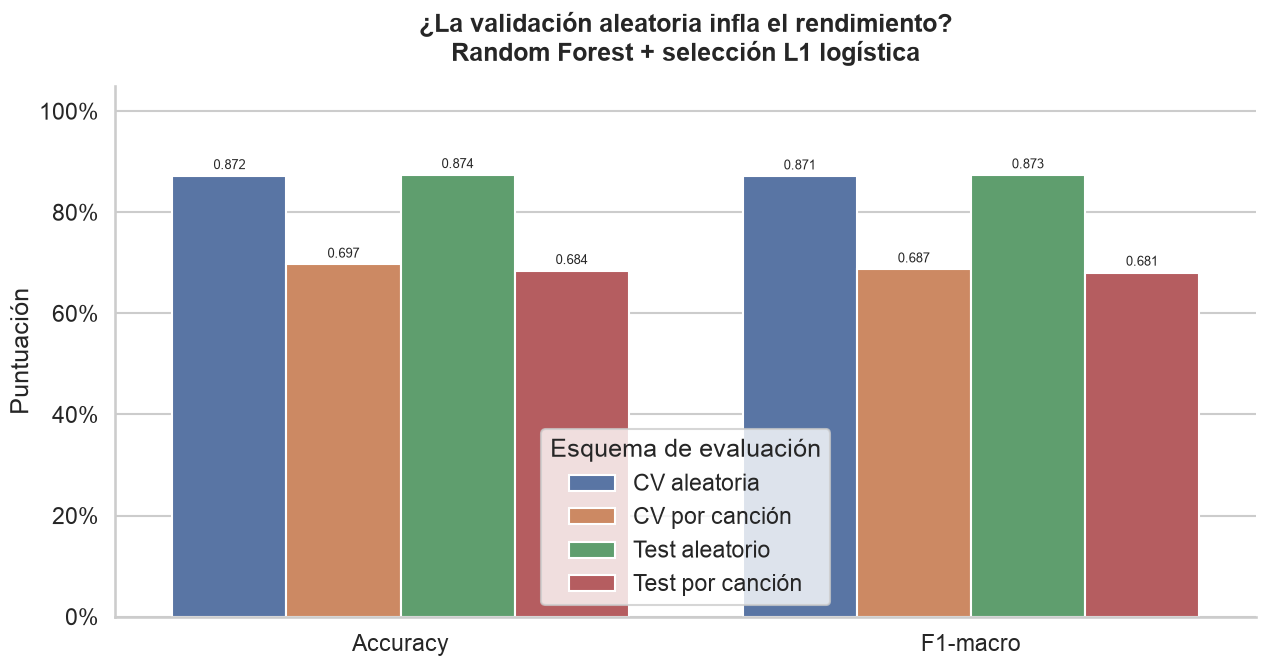

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score

# ============================================================
# 1. Preparar el dataset de segmentos de 3 segundos
# ============================================================

df = feat_3_df.copy()
df = df.dropna(subset=["label", "filename"]).reset_index(drop=True)

# Identificador de canción:
# blues.00000.0.wav -> blues.00000
groups = df["filename"].astype(str).apply(
    lambda f: ".".join(f.split(".")[:2])
).to_numpy()

# IMPORTANTE: filename NO es una característica del modelo
X = df.drop(columns=["label", "filename"])
y = df["label"].to_numpy()

# Si las características deben limpiarse o transformarse,
# hazlo sin ajustar transformaciones usando el test.
# Este ejemplo asume que X ya contiene características numéricas válidas.

# ============================================================
# 2. Crear dos particiones train/test
# ============================================================

# A) Partición aleatoria por segmento: puede compartir canciones
idx = np.arange(len(df))
idx_train_random, idx_test_random = train_test_split(
    idx,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

X_train_random = X.iloc[idx_train_random]
X_test_random = X.iloc[idx_test_random]
y_train_random = y[idx_train_random]
y_test_random = y[idx_test_random]
g_train_random = groups[idx_train_random]

# B) Partición por canción: ninguna canción se comparte
splitter = GroupShuffleSplit(
    n_splits=1, # AQUIÍ DEU TAMBÉ O COM? 
    test_size=0.20,
    random_state=42,
)

idx_train_group, idx_test_group = next(
    splitter.split(X, y, groups=groups)
)

X_train_group = X.iloc[idx_train_group]
X_test_group = X.iloc[idx_test_group]
y_train_group = y[idx_train_group]
y_test_group = y[idx_test_group]
g_train_group = groups[idx_train_group]
g_test_group = groups[idx_test_group]

# Comprobar el solapamiento entre canciones
overlap_random = set(groups[idx_train_random]) & set(groups[idx_test_random])
overlap_group = set(g_train_group) & set(g_test_group)

print("Canciones compartidas en split aleatorio:", len(overlap_random))
print("Canciones compartidas en split agrupado:", len(overlap_group))

# ============================================================
# 3. Crear los modelos y evaluar la validación cruzada
# ============================================================

def create_model(X_train, y_train, g_train, cv_mode):
    m = Models(
        X_train,
        y_train,
        groups=g_train,
        cv_mode=cv_mode,
    )

    m.build_models(
        ["random_forest"],
        selectors={
            "L1 logística": m.fs.make("l1_logistic"),
        },
    )
    return m


# Validación aleatoria: folds pueden compartir canciones
m_random = create_model(
    X_train_random, y_train_random, g_train_random, "random"
)

# Validación agrupada: folds separados por canción
m_group = create_model(
    X_train_group, y_train_group, g_train_group, "group"
)

cv_random = m_random.evaluate_all()
cv_group = m_group.evaluate_all()

model_name = "Random Forest | L1 logística"

print("\nCV aleatoria:")
print(cv_random[cv_random["Name"] == model_name].to_string(index=False))

print("\nCV agrupada por canción:")
print(cv_group[cv_group["Name"] == model_name].to_string(index=False))

# ============================================================
# 4. Entrenar cada modelo con su train y evaluar en su test
# ============================================================

def evaluate_test(model_container, model_name, X_train, y_train, X_test, y_test):
    estimator = clone(model_container.models[model_name])
    estimator.fit(X_train, y_train)
    pred = estimator.predict(X_test)

    return {
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test F1-macro": f1_score(y_test, pred, average="macro"),
    }


test_random = evaluate_test(
    m_random, model_name,
    X_train_random, y_train_random,
    X_test_random, y_test_random,
)

test_group = evaluate_test(
    m_group, model_name,
    X_train_group, y_train_group,
    X_test_group, y_test_group,
)

# ============================================================
# 5. Construir tabla comparativa
# ============================================================

def get_cv_row(result, name):
    row = result.loc[result["Name"] == name]
    if row.empty:
        raise ValueError(
            f"No se encontró '{name}'. Nombres disponibles: "
            f"{result['Name'].tolist()}"
        )
    return row.iloc[0]

r_cv = get_cv_row(cv_random, model_name)
g_cv = get_cv_row(cv_group, model_name)

comparison = pd.DataFrame(
    {
        "CV aleatoria": {
            "Accuracy": r_cv["Val Acc"],
            "F1-macro": r_cv["Val F1"],
        },
        "CV por canción": {
            "Accuracy": g_cv["Val Acc"],
            "F1-macro": g_cv["Val F1"],
        },
        "Test aleatorio": {
            "Accuracy": test_random["Test Accuracy"],
            "F1-macro": test_random["Test F1-macro"],
        },
        "Test por canción": {
            "Accuracy": test_group["Test Accuracy"],
            "F1-macro": test_group["Test F1-macro"],
        },
    }
)

print("\nComparación de rendimiento:")
print(comparison.round(4))

# Diferencia en puntos porcentuales: aleatorio - agrupado
print("\nDiferencia CV aleatoria - CV por canción (puntos porcentuales):")
print(((comparison["CV aleatoria"] - comparison["CV por canción"]) * 100).round(2))

# ============================================================
# 6. Gráfica comparativa
# ============================================================

plot_df = (
    comparison.rename_axis("Métrica")
    .reset_index()
    .melt(id_vars="Métrica", var_name="Evaluación", value_name="Score")
)

sns.set_theme(style="whitegrid", context="talk")

fig, ax = plt.subplots(figsize=(13, 7))

sns.barplot(
    data=plot_df,
    x="Métrica",
    y="Score",
    hue="Evaluación",
    ax=ax,
)

ax.set_ylim(0, 1.05)
ax.set_title(
    "¿La validación aleatoria infla el rendimiento?\n"
    "Random Forest + selección L1 logística",
    pad=18,
    weight="bold",
)
ax.set_ylabel("Puntuación")
ax.set_xlabel("")
ax.legend(title="Esquema de evaluación", loc="best")
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{v:.0%}")
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9,
    )

sns.despine()
plt.tight_layout()
plt.show()

### 2. Is 3 seconds enough to identify a genre? 

To answer this question we will compare the 30 second dataset performance with the 3 second one (the correct version). The 3 second 

In [28]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# ============================================================
# 0. Get the data and verify the song groups
# ============================================================

# Assumes you have already run your preprocessing code
# and retrieved X_train_30s, X_test_30s, etc.

def get_groups(prep, meta, split):
    """
    Get the song ID for every row, preserving row order.
    Tries the Preprocessing group attributes first, then metadata.
    """
    attr = f"groups_{split}"

    if hasattr(prep, attr):
        groups = getattr(prep, attr)
        if groups is not None and len(groups) == len(meta):
            return np.asarray(groups)

    for col in ["__group__", "group", "groups", "filename"]:
        if col in meta.columns:
            values = meta[col].astype(str).to_numpy()
            # Convert segment filenames to their song ID if needed.
            return np.array([".".join(v.split(".")[:2]) for v in values])

    raise ValueError(
        f"Could not find song groups for {split}. "
        "Inspect prep.get_meta() and the Preprocessing class."
    )


g_train_30s = get_groups(prep_30s, meta_train_30s, "train")
g_test_30s  = get_groups(prep_30s, meta_test_30s, "test")
g_train_3s  = get_groups(prep_3s, meta_train_3s, "train")
g_test_3s   = get_groups(prep_3s, meta_test_3s, "test")

# All 3-second segments from a song must be in the same partition.
assert set(g_train_3s).isdisjoint(set(g_test_3s))
assert set(g_train_30s).isdisjoint(set(g_test_30s))

# Confirm that both datasets use the same genre encoding.
classes_30s = np.asarray(prep_30s.encoder.classes_)
classes_3s = np.asarray(prep_3s.encoder.classes_)

assert np.array_equal(classes_30s, classes_3s), (
    "The genre encodings differ between datasets."
)

class_names = classes_30s
n_classes = len(class_names)
labels = np.arange(n_classes)

# ============================================================
# 1. Build the SAME model configurations for both datasets
# ============================================================

SELECTORS = {
    "Sin selección": "passthrough",
}

MODEL_KEYS = ["random_forest", "voting"]

models_30s = Models(
    X_train_30s,
    y_train_30s,
    groups=g_train_30s,
    cv_mode="group",
    label_encoder=prep_30s.encoder,
)

models_3s = Models(
    X_train_3s,
    y_train_3s,
    groups=g_train_3s,
    cv_mode="group",
    label_encoder=prep_3s.encoder,
)

models_30s.build_models(MODEL_KEYS, selectors=SELECTORS)
models_3s.build_models(MODEL_KEYS, selectors=SELECTORS)

print("Models available for 30s:")
print(list(models_30s.models.keys()))

print("\nModels available for 3s:")
print(list(models_3s.models.keys()))

Models available for 30s:
['Random Forest | Sin selección', 'Voting Ensemble | Sin selección']

Models available for 3s:
['Random Forest | Sin selección', 'Voting Ensemble | Sin selección']


In [29]:


# ============================================================
# 2. Generate out-of-fold predictions for grouped CV
# ============================================================


import time
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold

def grouped_oof_predictions(
    model_container, X, y, groups, n_splits=10
):
    y = np.asarray(y).ravel()
    groups = np.asarray(groups)

    X = X.reset_index(drop=True) if hasattr(X, "reset_index") else X

    cv = StratifiedGroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42,
    )

    # Generate folds once, so all models use the same splits
    folds = list(cv.split(X, y, groups))

    predictions = {}
    total_start = time.perf_counter()

    for model_num, (name, estimator) in enumerate(
        model_container.models.items(), start=1
    ):
        print(
            f"\n[{model_num}/{len(model_container.models)}] "
            f"Starting: {name}",
            flush=True,
        )

        pred = np.full(len(y), -1, dtype=int)

        for fold_num, (train_idx, val_idx) in enumerate(
            folds, start=1
        ):
            assert set(groups[train_idx]).isdisjoint(
                set(groups[val_idx])
            )

            start = time.perf_counter()

            print(
                f"  Fold {fold_num}/{n_splits}: "
                f"training on {len(train_idx):,} rows; "
                f"validating on {len(val_idx):,} rows...",
                flush=True,
            )

            fitted = clone(estimator)
            fitted.fit(X.iloc[train_idx], y[train_idx])
            pred[val_idx] = fitted.predict(X.iloc[val_idx])

            elapsed = time.perf_counter() - start

            print(
                f"  Fold {fold_num}/{n_splits} completed "
                f"in {elapsed:.1f} s",
                flush=True,
            )

        if np.any(pred == -1):
            raise RuntimeError(f"Some rows were not predicted for {name}")

        predictions[name] = pred

        print(
            f"Completed {name}. "
            f"Elapsed total: "
            f"{(time.perf_counter() - total_start) / 60:.1f} min",
            flush=True,
        )

    print(
        f"\nAll models completed in "
        f"{(time.perf_counter() - total_start) / 60:.1f} min.",
        flush=True,
    )

    return predictions



oof_30s = grouped_oof_predictions(
    models_30s, X_train_30s, y_train_30s, g_train_30s
)

oof_3s = grouped_oof_predictions(
    models_3s, X_train_3s, y_train_3s, g_train_3s
)


[1/2] Starting: Random Forest | Sin selección
  Fold 1/5: training on 640 rows; validating on 160 rows...
  Fold 1/5 completed in 2.1 s
  Fold 2/5: training on 640 rows; validating on 160 rows...
  Fold 2/5 completed in 1.8 s
  Fold 3/5: training on 640 rows; validating on 160 rows...
  Fold 3/5 completed in 1.7 s
  Fold 4/5: training on 640 rows; validating on 160 rows...
  Fold 4/5 completed in 1.5 s
  Fold 5/5: training on 640 rows; validating on 160 rows...
  Fold 5/5 completed in 1.7 s
Completed Random Forest | Sin selección. Elapsed total: 0.1 min

[2/2] Starting: Voting Ensemble | Sin selección
  Fold 1/5: training on 640 rows; validating on 160 rows...
  Fold 1/5 completed in 20.9 s
  Fold 2/5: training on 640 rows; validating on 160 rows...
  Fold 2/5 completed in 16.0 s
  Fold 3/5: training on 640 rows; validating on 160 rows...
  Fold 3/5 completed in 24.4 s
  Fold 4/5: training on 640 rows; validating on 160 rows...
  Fold 4/5 completed in 15.5 s
  Fold 5/5: training on 64

In [30]:
# ============================================================
# 3. Fit on the complete training partition and predict test
# ============================================================


import time
import numpy as np
from sklearn.base import clone

def final_test_predictions(
    model_container, X_train, y_train, X_test
):
    results = {}
    y_train = np.asarray(y_train).ravel()

    for i, (name, estimator) in enumerate(
        model_container.models.items(), start=1
    ):
        start = time.perf_counter()

        print(
            f"\nFinal fit [{i}/{len(model_container.models)}]: {name}",
            flush=True,
        )

        fitted = clone(estimator)
        fitted.fit(X_train, y_train)

        print("  Training finished. Predicting test set...", flush=True)
        results[name] = fitted.predict(X_test)

        print(
            f"  Finished in {time.perf_counter() - start:.1f} s",
            flush=True,
        )

    return results



test_pred_30s = final_test_predictions(
    models_30s, X_train_30s, y_train_30s, X_test_30s
)

test_pred_3s = final_test_predictions(
    models_3s, X_train_3s, y_train_3s, X_test_3s
)


Final fit [1/2]: Random Forest | Sin selección
  Training finished. Predicting test set...
  Finished in 2.8 s

Final fit [2/2]: Voting Ensemble | Sin selección
  Training finished. Predicting test set...
  Finished in 25.1 s

Final fit [1/2]: Random Forest | Sin selección
  Training finished. Predicting test set...
  Finished in 23.2 s

Final fit [2/2]: Voting Ensemble | Sin selección
  Training finished. Predicting test set...
  Finished in 265.5 s



===== METRICS: CROSS-VALIDATION AND FINAL TEST =====
      Evaluation   Duration                           Model  Accuracy  Precision macro  Recall macro  F1 macro
Cross-validation  3 seconds   Random Forest | Sin selección    0.6904           0.6874        0.6903    0.6874
Cross-validation 30 seconds   Random Forest | Sin selección    0.7712           0.7716        0.7712    0.7690
      Final test  3 seconds   Random Forest | Sin selección    0.7227           0.7187        0.7229    0.7190
      Final test 30 seconds   Random Forest | Sin selección    0.8150           0.8174        0.8150    0.8135
Cross-validation  3 seconds Voting Ensemble | Sin selección    0.7096           0.7051        0.7095    0.7065
Cross-validation 30 seconds Voting Ensemble | Sin selección    0.7650           0.7653        0.7650    0.7641
      Final test  3 seconds Voting Ensemble | Sin selección    0.7292           0.7271        0.7295    0.7248
      Final test 30 seconds Voting Ensemble | Sin selecció

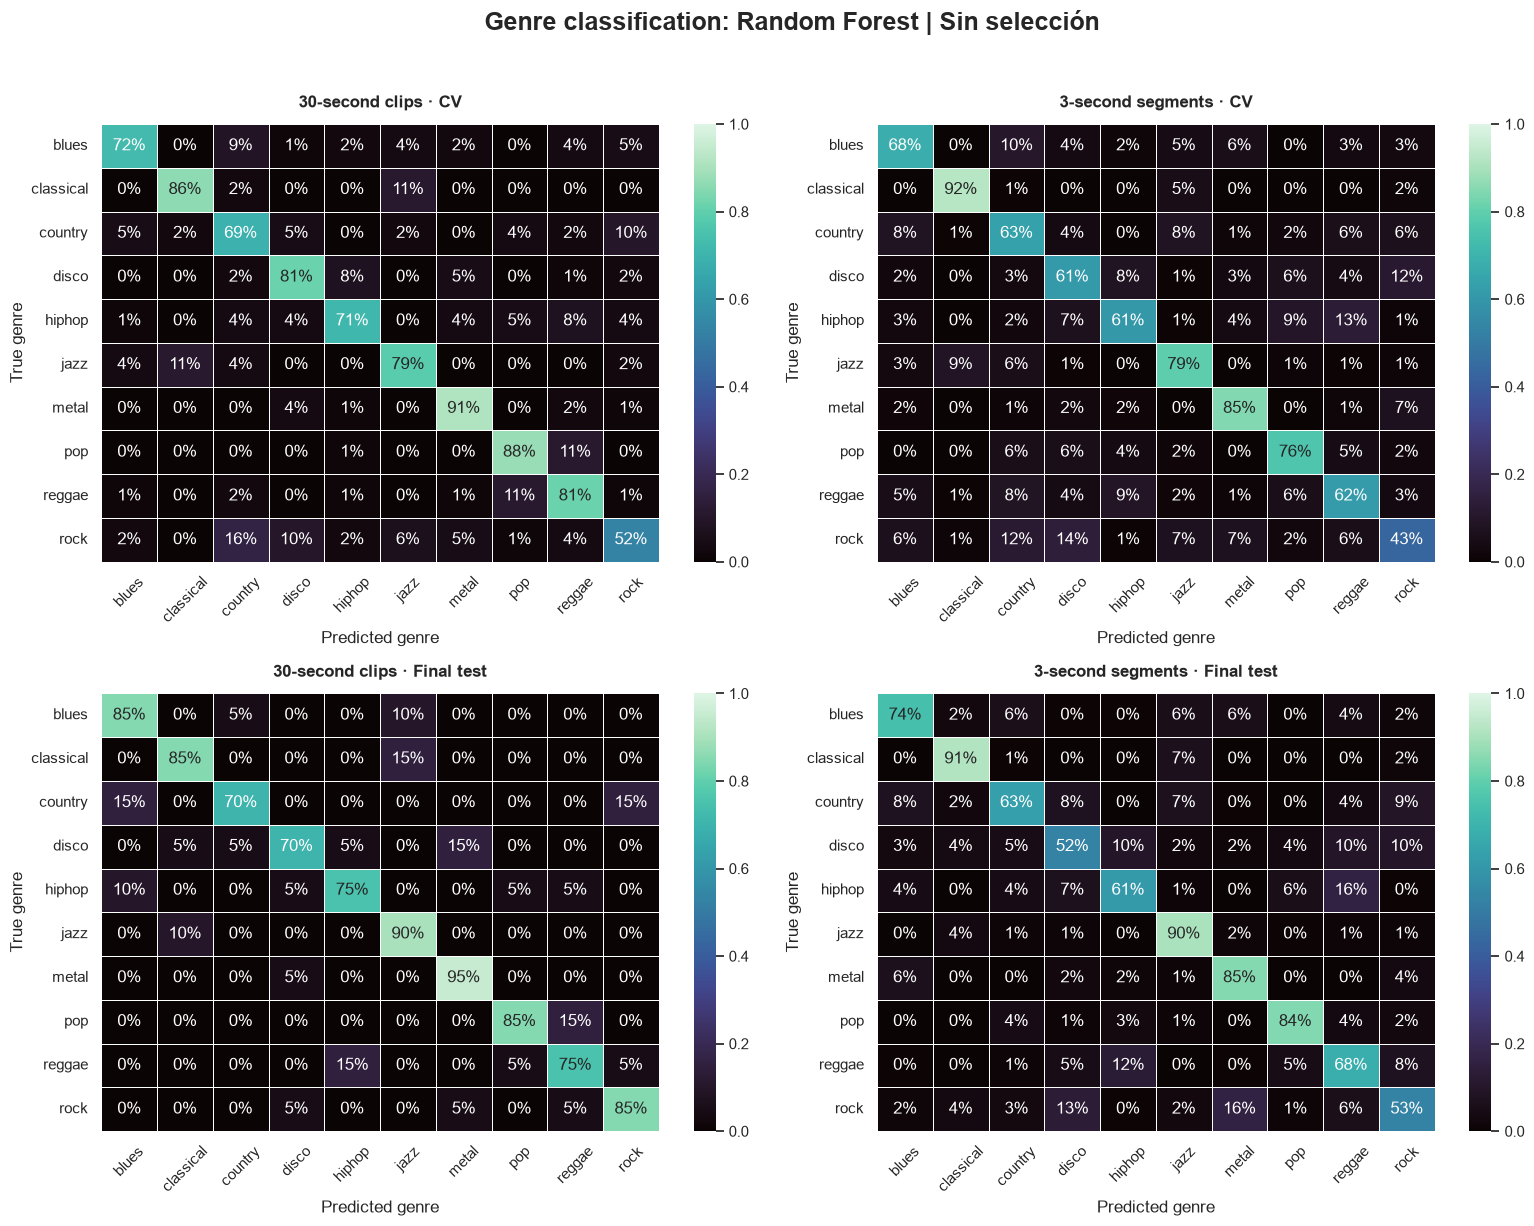

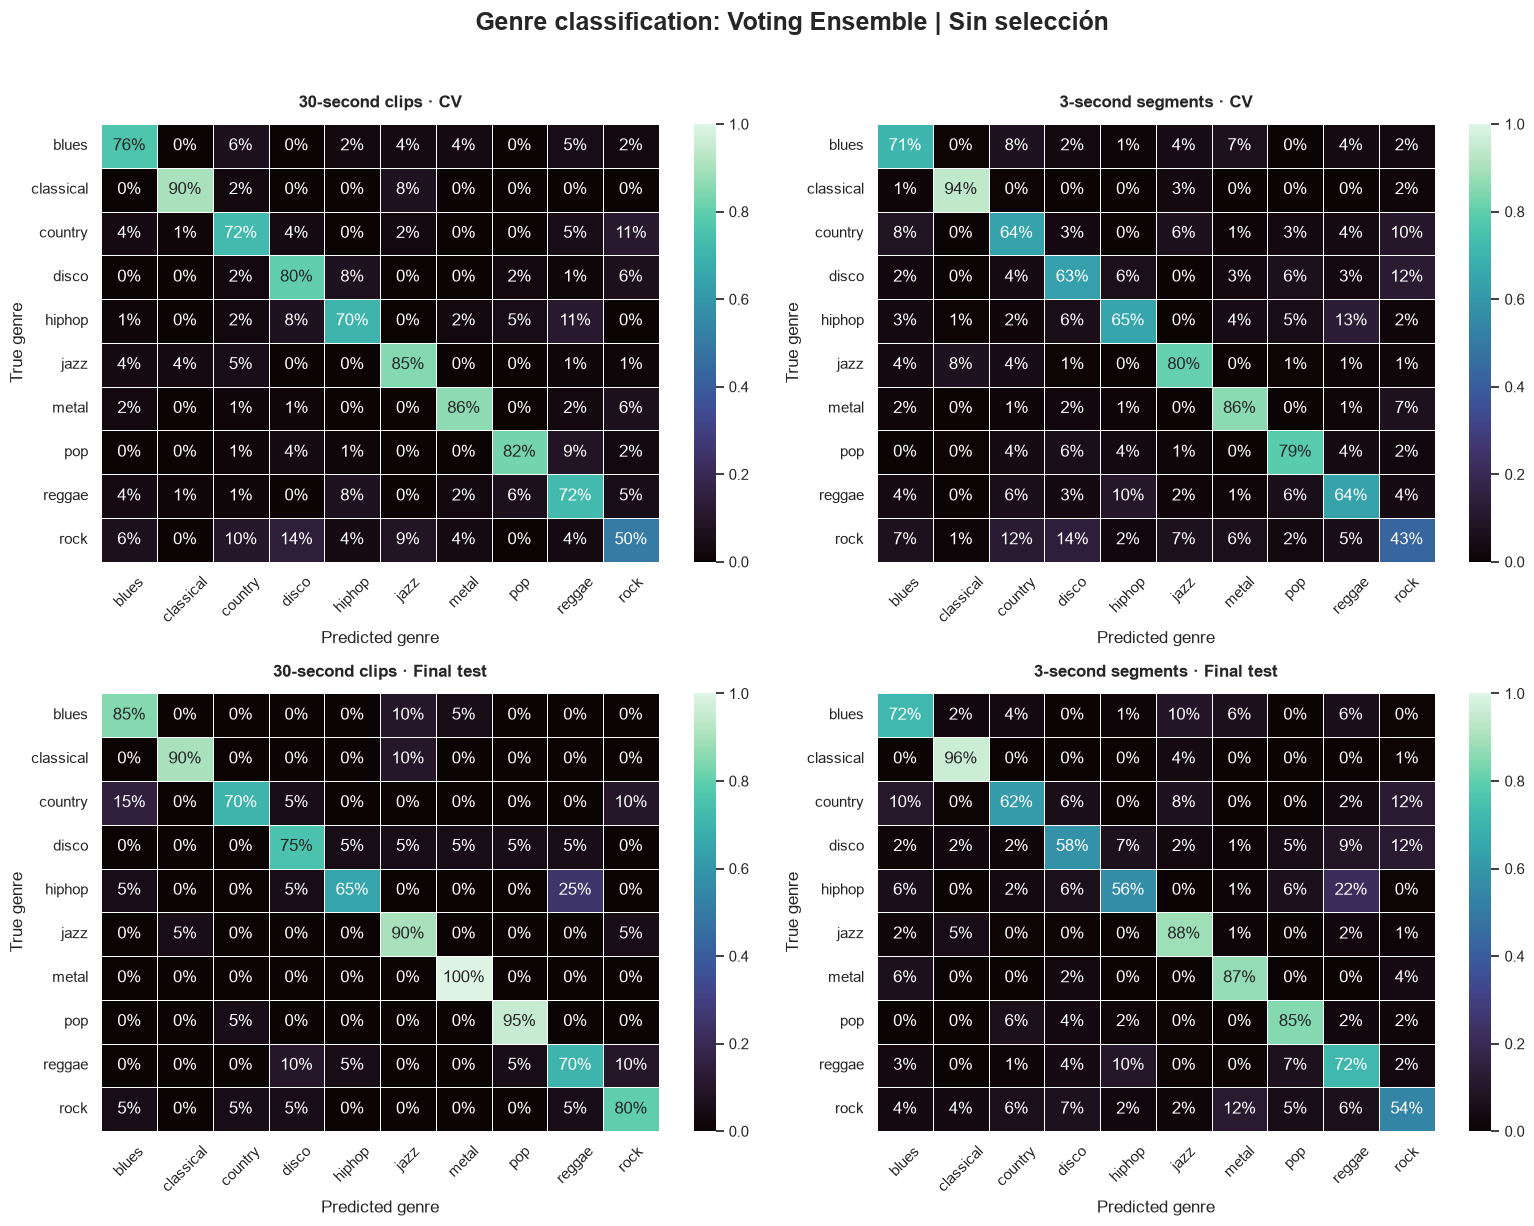

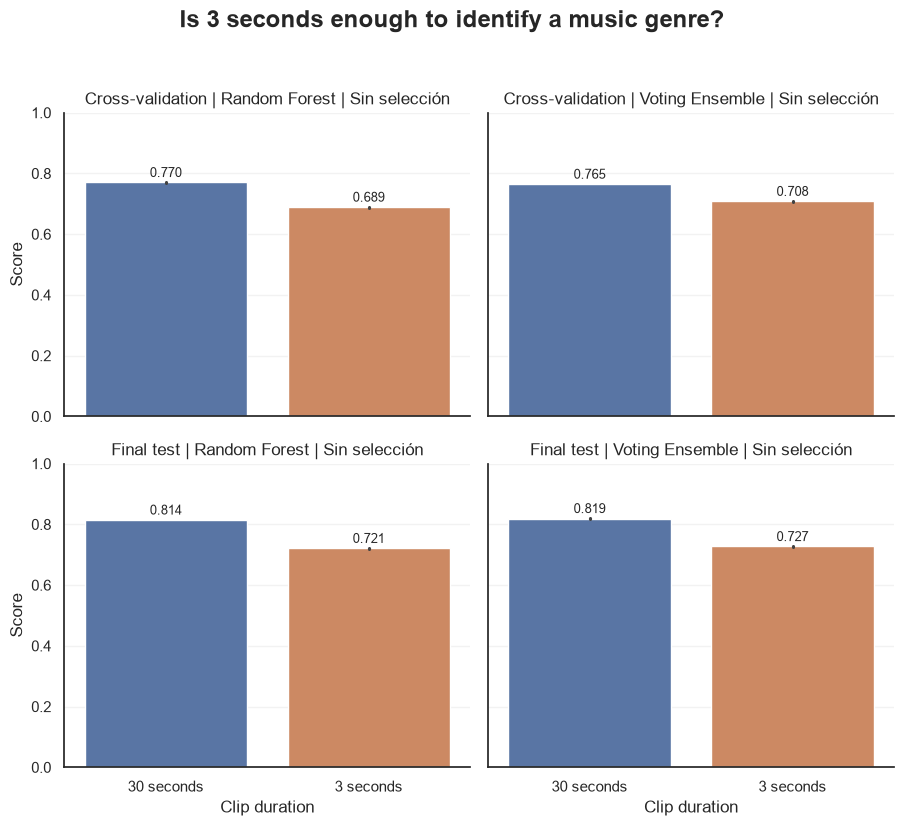

In [31]:


# ============================================================
# 4. Metrics: accuracy, macro precision/recall/F1
# ============================================================

def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1 macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
    }


rows = []

def add_metrics(split, duration, name, y_true, y_pred):
    row = {
        "Evaluation": split,
        "Duration": duration,
        "Model": name,
    }
    row.update(calculate_metrics(y_true, y_pred))
    rows.append(row)


for name, pred in oof_30s.items():
    add_metrics("Cross-validation", "30 seconds", name, y_train_30s, pred)

for name, pred in oof_3s.items():
    add_metrics("Cross-validation", "3 seconds", name, y_train_3s, pred)

for name, pred in test_pred_30s.items():
    add_metrics("Final test", "30 seconds", name, y_test_30s, pred)

for name, pred in test_pred_3s.items():
    add_metrics("Final test", "3 seconds", name, y_test_3s, pred)

metrics_df = pd.DataFrame(rows)

print("\n===== METRICS: CROSS-VALIDATION AND FINAL TEST =====")
print(
    metrics_df.sort_values(["Model", "Evaluation", "Duration"])
    .round(4)
    .to_string(index=False)
)

# ============================================================
# 5. Detailed classification reports
# ============================================================

def print_reports(title, y_true, predictions):
    print(f"\n{'=' * 75}\n{title}\n{'=' * 75}")

    for name, pred in predictions.items():
        print(f"\n--- {name} ---")
        print(
            classification_report(
                y_true,
                pred,
                labels=labels,
                target_names=[str(c) for c in class_names],
                zero_division=0,
            )
        )


print_reports("30s — GROUPED CROSS-VALIDATION", y_train_30s, oof_30s)
print_reports("3s — GROUPED CROSS-VALIDATION", y_train_3s, oof_3s)
print_reports("30s — FINAL TEST", y_test_30s, test_pred_30s)
print_reports("3s — FINAL TEST", y_test_3s, test_pred_3s)

# ============================================================
# 6. Confusion matrices: CV and test
# ============================================================

sns.set_theme(style="white", context="notebook")

def plot_confusion_comparison(
    model_name,
    pred_30_cv,
    pred_3_cv,
    pred_30_test,
    pred_3_test,
):
    """
    Four normalized confusion matrices:
    30s CV, 3s CV, 30s test, 3s test.
    Rows are normalized by the true genre.
    """
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    panels = [
        (
            axes[0, 0], y_train_30s, pred_30_cv,
            "30-second clips · CV"
        ),
        (
            axes[0, 1], y_train_3s, pred_3_cv,
            "3-second segments · CV"
        ),
        (
            axes[1, 0], y_test_30s, pred_30_test,
            "30-second clips · Final test"
        ),
        (
            axes[1, 1], y_test_3s, pred_3_test,
            "3-second segments · Final test"
        ),
    ]

    for ax, y_true, y_pred, title in panels:
        cm = confusion_matrix(
            y_true,
            y_pred,
            labels=labels,
            normalize="true",
        )

        sns.heatmap(
            cm,
            annot=True,
            fmt=".0%",
            cmap="mako",
            vmin=0,
            vmax=1,
            xticklabels=class_names,
            yticklabels=class_names,
            linewidths=0.5,
            linecolor="white",
            ax=ax,
            cbar=True,
        )

        ax.set_title(title, weight="bold", pad=12)
        ax.set_xlabel("Predicted genre")
        ax.set_ylabel("True genre")
        ax.tick_params(axis="x", rotation=45)
        ax.tick_params(axis="y", rotation=0)

    fig.suptitle(
        f"Genre classification: {model_name}",
        fontsize=18,
        weight="bold",
        y=1.02,
    )

    plt.tight_layout()
    plt.show()


for name in models_30s.models.keys():
    plot_confusion_comparison(
        model_name=name,
        pred_30_cv=oof_30s[name],
        pred_3_cv=oof_3s[name],
        pred_30_test=test_pred_30s[name],
        pred_3_test=test_pred_3s[name],
    )

# ============================================================
# 7. Beautiful summary chart: 30s vs 3s
# ============================================================

plot_metrics = metrics_df.melt(
    id_vars=["Evaluation", "Duration", "Model"],
    value_vars=["Accuracy", "F1 macro"],
    var_name="Metric",
    value_name="Score",
)

g = sns.catplot(
    data=plot_metrics,
    x="Duration",
    y="Score",
    hue="Duration",
    col="Model",
    row="Evaluation",
    kind="bar",
    height=4,
    aspect=1.15,
    sharey=True,
    legend=False,
)

g.set(ylim=(0, 1.0))
g.set_axis_labels("Clip duration", "Score")
g.set_titles(row_template="{row_name}", col_template="{col_name}")

for ax in g.axes.flat:
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=2, fontsize=9)

g.figure.suptitle(
    "Is 3 seconds enough to identify a music genre?",
    fontsize=17,
    weight="bold",
    y=1.03,
)

plt.tight_layout()
plt.show()


### 3. Combining the short windows improves the whole window results? 

This question can be interpreted as two diferent things:
- Combining the predictions of the segments
- Combining the features before training the models

In our case we are going to evaluate the first one. We will see if with different combinations of the predicted probabilities of the segments (via the mean, or a vote...) will improve the results and maybe get better results than the long windows. 

[30s] Fitting Random Forest | Sin selección on 800 rows...
[30s] Done in 1.2 s
[3s] Fitting Random Forest | Sin selección on 7,992 rows...
[3s] Done in 8.7 s

RESULTS: Random Forest — held-out test songs
Songs evaluated in both datasets: 200


,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Method,,,,
30s - Full song,0.815,0.8174,0.815,0.8135
3s - Log-sum,0.795,0.7930,0.795,0.7927
3s - Mean,0.790,0.7862,0.790,0.7850
3s - Sum,0.790,0.7862,0.790,0.7850
3s - Vote,0.790,0.7852,0.790,0.7853
3s - Max,0.775,0.7778,0.775,0.7696


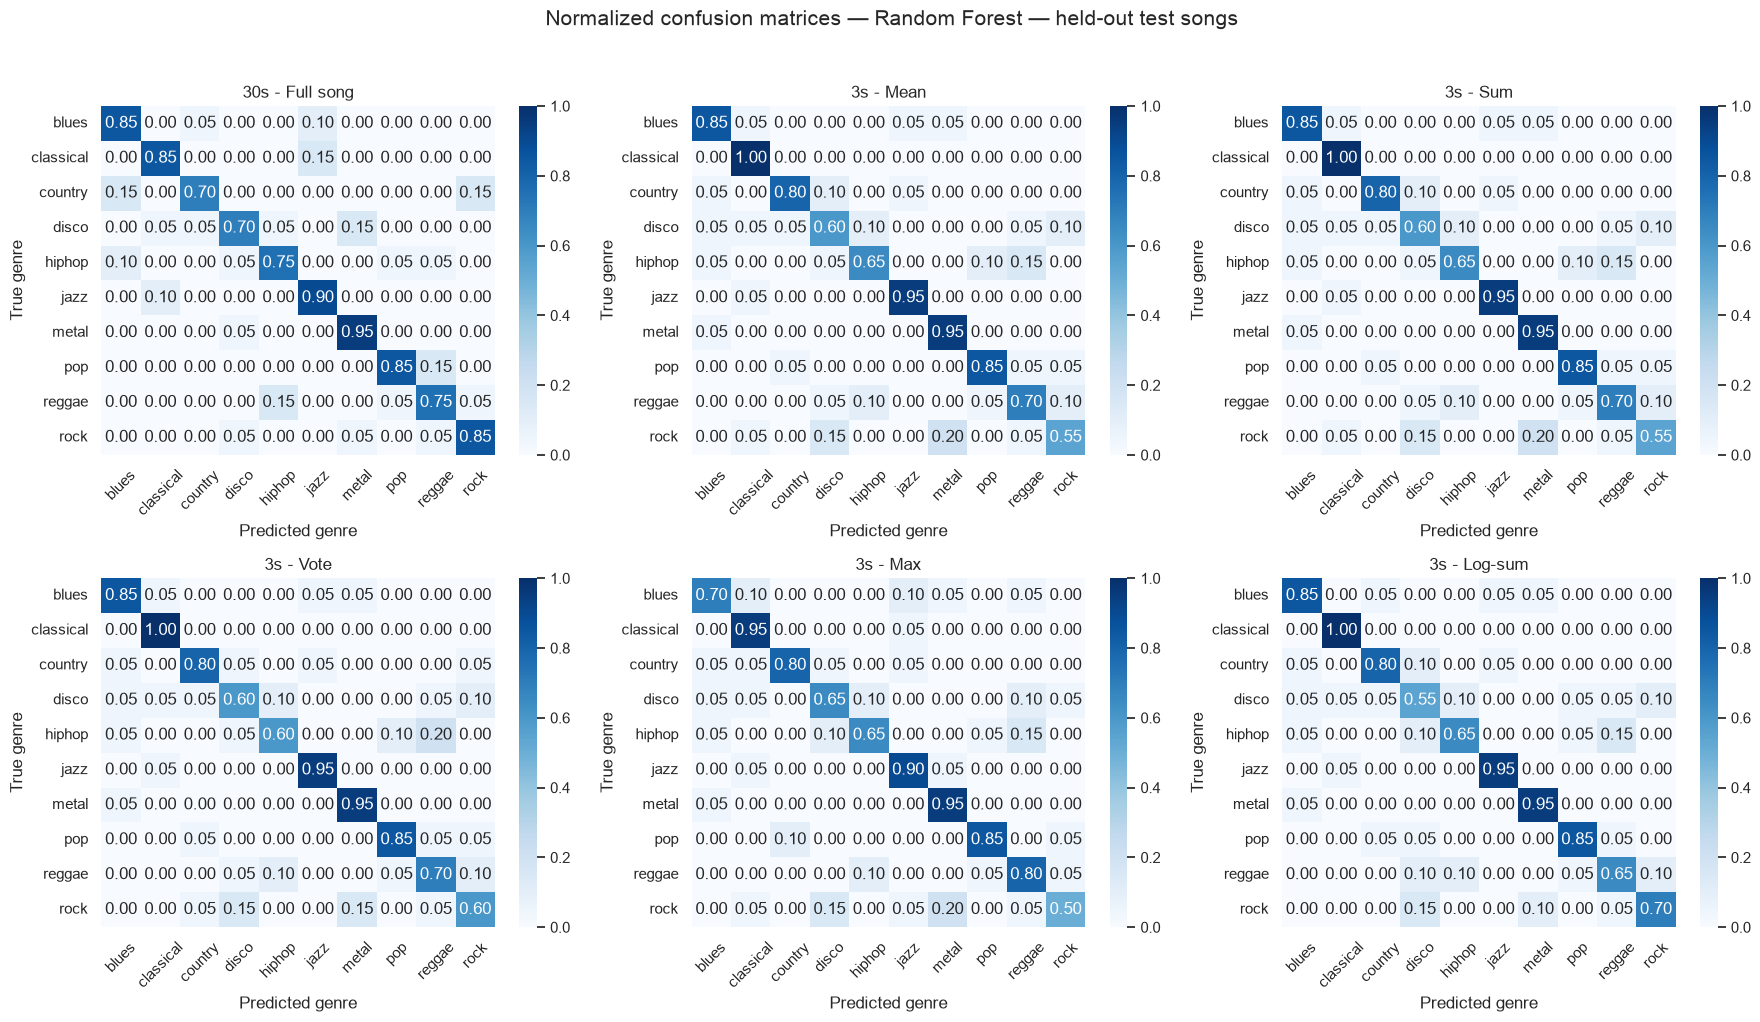

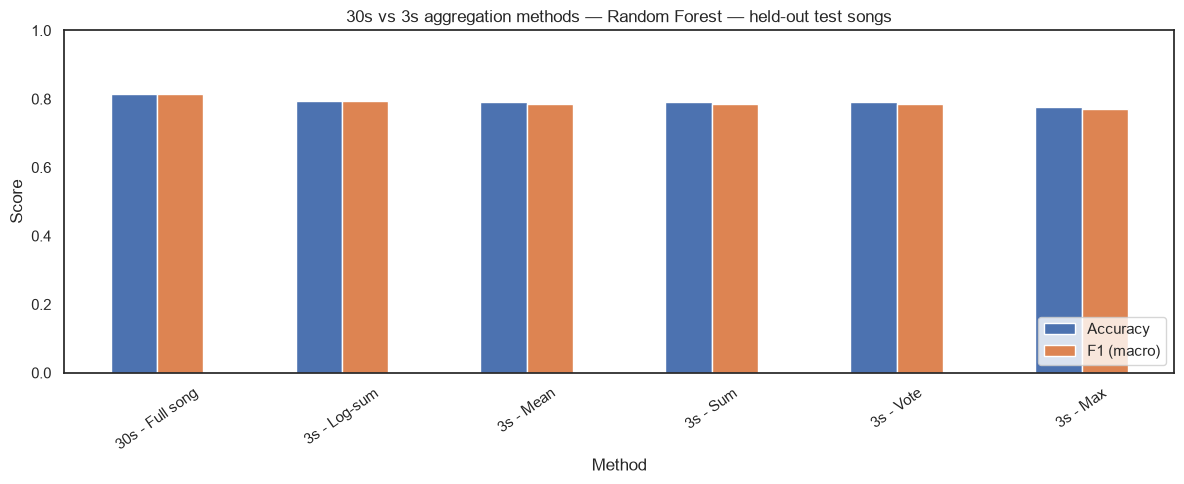

[30s] Fitting Voting Ensemble | Sin selección on 800 rows...
[30s] Done in 1.4 s
[3s] Fitting Voting Ensemble | Sin selección on 7,992 rows...
[3s] Done in 12.1 s

RESULTS: Voting Ensemble — held-out test songs
Songs evaluated in both datasets: 200


,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Method,,,,
30s - Full song,0.820,0.8237,0.820,0.8183
3s - Mean,0.805,0.8043,0.805,0.8006
3s - Sum,0.805,0.8043,0.805,0.8006
3s - Vote,0.790,0.7916,0.790,0.7862
3s - Log-sum,0.790,0.7890,0.790,0.7855
3s - Max,0.775,0.7777,0.775,0.7651


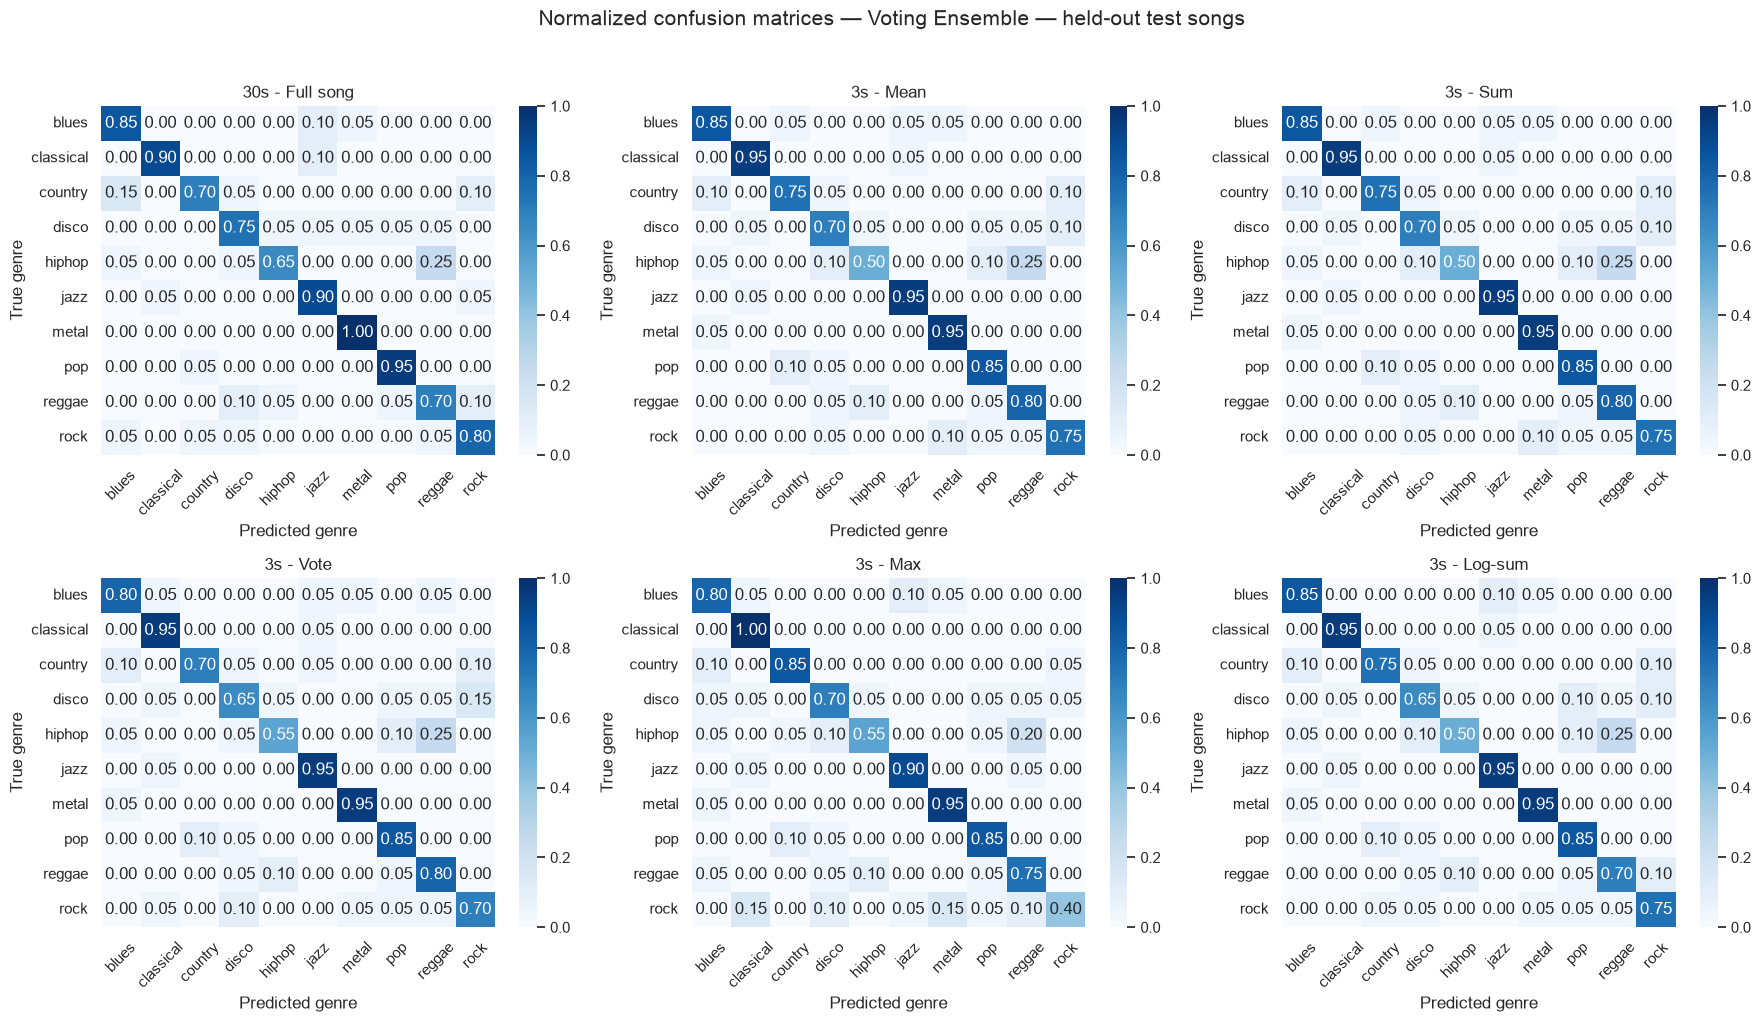

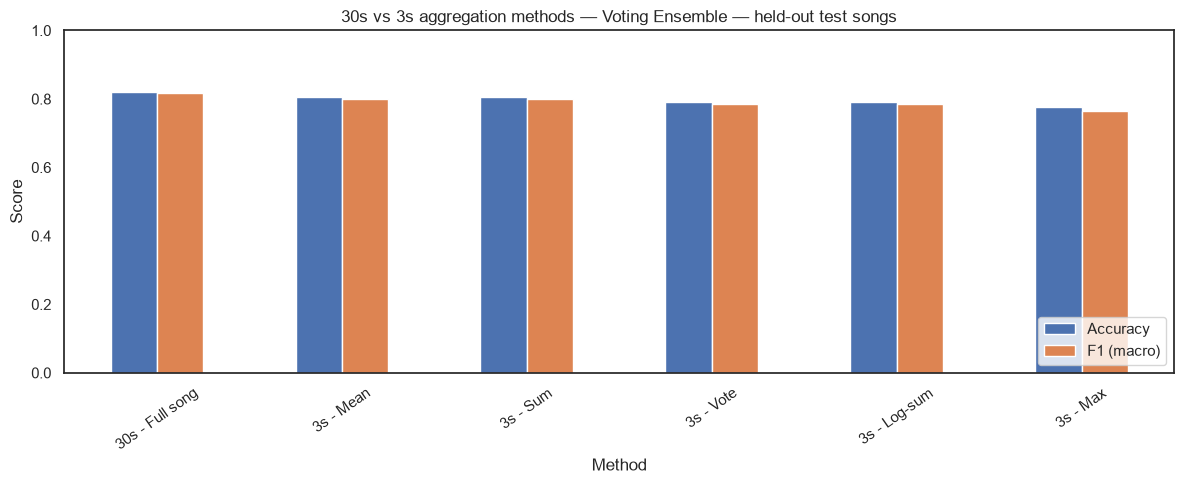

Accuracy  Precision (macro)  Recall (macro)  \
Model           Method                                                         
Random Forest   30s - Full song     0.815             0.8174           0.815   
                3s - Log-sum        0.795             0.7930           0.795   
                3s - Mean           0.790             0.7862           0.790   
                3s - Sum            0.790             0.7862           0.790   
                3s - Vote           0.790             0.7852           0.790   
                3s - Max            0.775             0.7778           0.775   
Voting Ensemble 30s - Full song     0.820             0.8237           0.820   
                3s - Mean           0.805             0.8043           0.805   
                3s - Sum            0.805             0.8043           0.805   
                3s - Vote           0.790             0.7916           0.790   
                3s - Log-sum        0.790             0.7890           0.790   
                3s - Max            0.775             0.7777           0.775   

                                 F1 (macro)  
Model           Method                       
Random Forest   30s - Full song      0.8135  
                3s - Log-sum         0.7927  
                3s - Mean            0.7850  
                3s - Sum             0.7850  
                3s - Vote            0.7853  
                3s - Max             0.7696  
Voting Ensemble 30s - Full song      0.8183  
                3s - Mean            0.8006  
                3s - Sum             0.8006  
                3s - Vote            0.7862  
                3s - Log-sum         0.7855  
                3s - Max             0.7651

Accuracy gain vs 30s full song (percentage points):


Method,3s - Log-sum,3s - Max,3s - Mean,3s - Sum,3s - Vote
Model,,,,,
Random Forest,-2.0,-4.0,-2.5,-2.5,-2.5
Voting Ensemble,-3.0,-4.5,-1.5,-1.5,-3.0


Best method per model:
  Random Forest: 30s - Full song (accuracy = 0.8150)
  Voting Ensemble: 30s - Full song (accuracy = 0.8200)


In [36]:
# %% [Cell 1] Imports and helper functions
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)


def song_id(name):
    """'blues.00000.3.wav', 'blues.00000.wav', 'blues.00000' -> 'blues.00000'."""
    return ".".join(str(name).split(".")[:2])


def to_song_ids(groups):
    return np.array([song_id(g) for g in np.asarray(groups)])


def _final_estimator(estimator):
    return estimator.steps[-1][1] if isinstance(estimator, Pipeline) else estimator


# Fitted models are cached here, so re-running the cells does not retrain.
if "fitted_q3" not in globals():
    fitted_q3 = {}


def get_fitted_model(model_container, name, X_train, y_train, tag):
    """
    The models stored in Models.models are UNFITTED templates
    (Question 2 only fitted clones of them and then discarded the clones).
    Here a clone is fitted on the full training partition and kept.
    """
    key = (tag, name)
    if key in fitted_q3:
        print(f"[{tag}] {name}: using cached fitted model")
        return fitted_q3[key]

    if name not in model_container.models:
        raise KeyError(
            f"'{name}' not found. Available: {list(model_container.models)}"
        )

    estimator = clone(model_container.models[name])

    # Hard voting has no predict_proba -> switch to soft voting
    final = _final_estimator(estimator)
    if isinstance(final, VotingClassifier) and final.voting == "hard":
        final.set_params(voting="soft")
        print(f"[{tag}] {name}: VotingClassifier switched to voting='soft' "
              "to obtain probabilities")

    print(f"[{tag}] Fitting {name} on {len(X_train):,} rows...", flush=True)
    start = time.perf_counter()
    estimator.fit(X_train, np.asarray(y_train).ravel())
    print(f"[{tag}] Done in {time.perf_counter() - start:.1f} s", flush=True)

    if not hasattr(estimator, "predict_proba"):
        raise AttributeError(
            f"{name} has no predict_proba. All its estimators must support "
            "probabilities (e.g. SVC(probability=True))."
        )

    fitted_q3[key] = estimator
    return estimator


# ---------------------------------------------------------
# 1. Aggregate all 3-second segments belonging to each song
# ---------------------------------------------------------

def aggregate_3s_by_song(proba_3s, y_3s, groups_3s, classes):
    """
    Song-level scores from segment probabilities using:
    mean, sum, majority vote, max per class and sum of log-probabilities.
    """
    proba_3s = np.asarray(proba_3s, dtype=float)
    y_3s = np.asarray(y_3s).ravel()
    groups_3s = np.asarray(groups_3s)
    classes = np.asarray(classes)

    if not (len(proba_3s) == len(y_3s) == len(groups_3s)):
        raise ValueError("Probabilities, labels and groups must have equal length.")

    song_ids = list(dict.fromkeys(groups_3s.tolist()))

    y_song = []
    aggregated = {
        "3s - Mean": [],
        "3s - Sum": [],
        "3s - Vote": [],
        "3s - Max": [],
        "3s - Log-sum": [],
    }

    for song in song_ids:
        idx = groups_3s == song
        P = proba_3s[idx]
        labels = np.unique(y_3s[idx])

        if len(labels) != 1:
            raise ValueError(f"Song {song} has inconsistent labels: {labels}")
        y_song.append(labels[0])

        # A. Mean probabilities
        aggregated["3s - Mean"].append(P.mean(axis=0))

        # B. Sum probabilities (same argmax as the mean; kept for completeness)
        aggregated["3s - Sum"].append(P.sum(axis=0))

        # C. Majority vote; ties broken by total probability of the tied classes
        segment_pred = np.argmax(P, axis=1)
        votes = np.bincount(segment_pred, minlength=len(classes))
        tied = np.flatnonzero(votes == votes.max())
        vote_scores = np.zeros(len(classes))
        if len(tied) == 1:
            vote_scores[tied[0]] = 1.0
        else:
            vote_scores[tied] = P[:, tied].sum(axis=0)
        aggregated["3s - Vote"].append(vote_scores)

        # D. Maximum probability per class
        aggregated["3s - Max"].append(P.max(axis=0))

        # E. Sum of log-probabilities (clipping avoids log(0))
        aggregated["3s - Log-sum"].append(
            np.log(np.clip(P, 1e-12, 1.0)).sum(axis=0)
        )

    aggregated = {m: np.vstack(v) for m, v in aggregated.items()}
    return song_ids, np.asarray(y_song), aggregated


# ---------------------------------------------------------
# 2. Compare 30-second predictions with aggregated 3s ones
# ---------------------------------------------------------

def compare_durations(
    proba_30s, y_30s, groups_30s,
    proba_3s, y_3s, groups_3s,
    classes, class_names,
    title="Test set",
    plot=True,
    verbose=True,
):
    proba_30s = np.asarray(proba_30s, dtype=float)
    proba_3s = np.asarray(proba_3s, dtype=float)
    y_30s = np.asarray(y_30s).ravel()
    y_3s = np.asarray(y_3s).ravel()
    groups_30s = to_song_ids(groups_30s)
    groups_3s = to_song_ids(groups_3s)
    classes = np.asarray(classes)
    class_names = np.asarray(class_names)

    if proba_30s.shape != (len(y_30s), len(classes)):
        raise ValueError(f"30s probabilities have shape {proba_30s.shape}.")
    if proba_3s.shape != (len(y_3s), len(classes)):
        raise ValueError(f"3s probabilities have shape {proba_3s.shape}.")
    if len(groups_30s) != len(y_30s) or len(groups_3s) != len(y_3s):
        raise ValueError("Groups and labels have different lengths.")

    # 3s: one score vector per song for each aggregation method
    songs_3s, y_song_3s, agg_3s = aggregate_3s_by_song(
        proba_3s, y_3s, groups_3s, classes
    )
    map_3 = {s: i for i, s in enumerate(songs_3s)}

    # 30s: exactly one row per song
    counts = pd.Series(groups_30s).value_counts()
    if (counts > 1).any():
        raise ValueError(f"Songs with several 30s rows: {list(counts[counts > 1].index[:5])}")
    map_30 = {s: i for i, s in enumerate(groups_30s)}

    # Evaluate exactly the same songs in both datasets
    common_songs = [s for s in groups_30s if s in map_3]
    if not common_songs:
        raise ValueError("No song IDs match between the 30s and 3s test sets.")

    missing = len(set(groups_30s) ^ set(songs_3s))
    if missing:
        print(f"Warning: {missing} songs are only in one of the two test sets "
              "and are excluded.")

    idx30 = np.array([map_30[s] for s in common_songs])
    idx3 = np.array([map_3[s] for s in common_songs])

    y_true = y_30s[idx30]
    if not np.array_equal(y_true, y_song_3s[idx3]):
        raise ValueError("True genres differ between the 30s and 3s datasets.")

    probabilities = {"30s - Full song": proba_30s[idx30]}
    for method, P in agg_3s.items():
        probabilities[method] = P[idx3]

    # ---------------- Metrics ----------------
    rows, predictions = [], {}
    for method, P in probabilities.items():
        y_pred = classes[np.argmax(P, axis=1)]
        predictions[method] = y_pred
        rows.append({
            "Method": method,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision (macro)": precision_score(
                y_true, y_pred, labels=classes, average="macro", zero_division=0),
            "Recall (macro)": recall_score(
                y_true, y_pred, labels=classes, average="macro", zero_division=0),
            "F1 (macro)": f1_score(
                y_true, y_pred, labels=classes, average="macro", zero_division=0),
        })

    results = (pd.DataFrame(rows).set_index("Method")
               .sort_values("Accuracy", ascending=False))

    print(f"\n{'=' * 65}\nRESULTS: {title}")
    print(f"Songs evaluated in both datasets: {len(common_songs)}\n{'=' * 65}")
    display(results.round(4))

    if verbose:
        for method, y_pred in predictions.items():
            print(f"\n--- {method} ---")
            print(classification_report(
                y_true, y_pred, labels=classes,
                target_names=class_names, zero_division=0))

    if plot:
        # Confusion matrices
        n = len(predictions)
        ncols = 3
        nrows = int(np.ceil(n / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows),
                                 squeeze=False)
        axes = axes.ravel()
        for i, (method, y_pred) in enumerate(predictions.items()):
            cm = confusion_matrix(y_true, y_pred, labels=classes, normalize="true")
            sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                        xticklabels=class_names, yticklabels=class_names,
                        ax=axes[i])
            axes[i].set_title(method)
            axes[i].set_xlabel("Predicted genre")
            axes[i].set_ylabel("True genre")
            axes[i].tick_params(axis="x", rotation=45)
            axes[i].tick_params(axis="y", rotation=0)
        for j in range(n, len(axes)):
            axes[j].set_visible(False)
        fig.suptitle(f"Normalized confusion matrices — {title}", fontsize=15, y=1.02)
        plt.tight_layout()
        plt.show()

        # Metric bar chart
        ax = results[["Accuracy", "F1 (macro)"]].plot(
            kind="bar", figsize=(12, 5), ylim=(0, 1), rot=35)
        ax.set_title(f"30s vs 3s aggregation methods — {title}")
        ax.set_ylabel("Score")
        ax.set_xlabel("Method")
        ax.legend(loc="lower right")
        plt.tight_layout()
        plt.show()

    return results, predictions, y_true, common_songs


# %% [Cell 2] Fit the models (once) and compare 30s vs aggregated 3s
MODEL_NAMES = [
    "Random Forest | Sin selección",
    "Voting Ensemble | Sin selección",
]

# Song ID of every test row (same row order as X_test)
g_test_30s = to_song_ids(prep_30s.groups_test)
g_test_3s = to_song_ids(prep_3s.groups_test)
assert len(g_test_30s) == len(X_test_30s)
assert len(g_test_3s) == len(X_test_3s)

class_names = np.asarray(prep_30s.encoder.classes_)

all_results = {}
all_predictions = {}

for model_name in MODEL_NAMES:
    model_30 = get_fitted_model(models_30s, model_name,
                                X_train_30s, y_train_30s, tag="30s")
    model_3 = get_fitted_model(models_3s, model_name,
                               X_train_3s, y_train_3s, tag="3s")

    # Column order of predict_proba = model.classes_
    classes = np.asarray(model_30.classes_)
    assert np.array_equal(classes, np.asarray(model_3.classes_)), (
        "30s and 3s models have different class orders."
    )
    names = class_names[classes] if np.issubdtype(classes.dtype, np.integer) else classes

    proba_30_test = model_30.predict_proba(X_test_30s)
    proba_3_test = model_3.predict_proba(X_test_3s)

    short_name = model_name.split(" | ")[0]
    results, predictions, y_true, common_songs = compare_durations(
        proba_30s=proba_30_test,
        y_30s=y_test_30s,
        groups_30s=g_test_30s,
        proba_3s=proba_3_test,
        y_3s=y_test_3s,
        groups_3s=g_test_3s,
        classes=classes,
        class_names=names,
        title=f"{short_name} — held-out test songs",
        verbose=False,   # True to print a classification report per method
    )

    all_results[short_name] = results
    all_predictions[short_name] = predictions


# %% [Cell 3] Final comparison table
comparison = pd.concat(all_results, names=["Model", "Method"])
display(comparison.round(4))

# Gain of each 3s aggregation over the 30s model (percentage points)
gain = (
    comparison["Accuracy"].unstack("Method")
    .sub(comparison["Accuracy"].unstack("Method")["30s - Full song"], axis=0)
    .drop(columns="30s - Full song")
    * 100
)
print("Accuracy gain vs 30s full song (percentage points):")
display(gain.round(2))

best = comparison["Accuracy"].groupby(level="Model").idxmax()
print("Best method per model:")
for model, (_, method) in best.items():
    print(f"  {model}: {method} "
          f"(accuracy = {comparison.loc[(model, method), 'Accuracy']:.4f})")

In [ ]:
does combining the 3-second windows beat the full 30-second window?

No. Combining the segment predictions comes close to the 30-second model but never beats it. For both models the best result is the full-song prediction: 0.815 accuracy for the Random Forest and 0.820 for the Voting Ensemble. The best aggregation is 2 to 3 points behind. For the Random Forest that is Log-sum (0.795), and for the Voting Ensemble it is Mean (0.805). Mean and Sum always give the same predictions, because the sum is just the mean multiplied by the number of segments, so the class with the highest score doesn’t change. Mean, Sum, Vote and Log-sum all perform similarly (0.790–0.805). Max is the worst method for both models (0.775). Max scores each genre by its single most confident segment, so one misleading 3-second window is enough to change the prediction for the whole song. Still, aggregation clearly helps. Ten noisy 3-second predictions combined give results almost as good as a model that sees the whole song, so short windows contain most of the information needed to identify the genre.

The overall accuracy hides clear differences between genres. Comparing recall per genre (the diagonals of the confusion matrices) between the 30s model and the 3s Mean aggregation:

Genre	RF 30s	RF 3s Mean	Voting 30s	Voting 3s Mean	Better with
classical	0.85	1.00	0.90	0.95	3s aggregated
country	0.70	0.80	0.70	0.75	3s aggregated
jazz	0.90	0.95	0.90	0.95	3s aggregated
blues	0.85	0.85	0.85	0.85	No difference
metal	0.95	0.95	1.00	0.95	≈ No difference
pop	0.85	0.85	0.95	0.85	≈ 30s
reggae	0.75	0.70	0.70	0.80	Depends on model
disco	0.70	0.60	0.75	0.70	30s
hiphop	0.75	0.65	0.65	0.50	30s
rock	0.85	0.55	0.80	0.75	30s

Classical, jazz and country improve with aggregated 3-second windows in both models. These genres have a fairly uniform sound throughout the song (instrumentation, timbre, harmony). Almost every 3-second segment carries the genre’s signature, so averaging many segments reduces noise and makes the decision more reliable.

Rock, hip-hop and disco are clearly better with the full 30-second window. Rock is the most extreme case: with the Random Forest its recall drops from 0.85 to 0.55, because 20% of rock songs are predicted as metal and 15% as disco. Hip-hop is often confused with reggae (up to 25% with the Voting Ensemble) and pop. These genres are defined less by the sound of any one moment and more by patterns that unfold over time, like rhythm, beat structure, and the contrast between sections such as verses, choruses and solos. A single 3-second segment of a rock song can sound like metal, or a hip-hop beat can sound like reggae. When many segments are ambiguous in the same way, aggregating them can’t fix the mistake. The 30-second features describe the song as a whole and capture that longer structure.

The differences between methods are small and should be read with care. The test set has 200 songs (20 per genre), so a 0.05 change in a genre’s recall is one song, and the overall gaps of 1.5–4.5 points correspond to only 3–9 songs. All the results also come from a single train/test split. A cross-validation with grouped folds would be needed to confirm that the 30-second model is really better rather than just slightly luckier on this split. Even so, the pattern is consistent across both models: aggregating 3-second windows is a strong alternative that works best for genres with a uniform sound, while the 30-second representation is still better overall and especially for genres that depend on rhythm and structure over time.